
# SentinelAI
## Network Intrusion Detection System

### 1. Project Overview

SentinelAI is a Machine Learning-based cybersecurity
system designed to detect malicious network traffic.

The system analyzes network flow features to identify
normal and malicious network activities.

### 2. Dataset Information

- Dataset: CIC-IDS2017
- Domain: Cybersecurity
- Task: Network Intrusion Detection
- Problem Type: Multi-class Classification
- Data Format: CSV

### 3. EDA Objectives

- Understand the dataset structure.
- Explore network traffic features.
- Identify missing values.
- Detect duplicate records.
- Analyze attack distribution.
- Understand data quality issues.




## 1. Import Libraries

In this section, we import the libraries required
for data manipulation, numerical operations,
visualization, and file handling.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob

import warnings
warnings.filterwarnings("ignore")



## 2. Loading Dataset

In this section, we define the dataset directory
and retrieve all available CSV files.


In [2]:
DATA_PATH = "../dataset/raw"

files = glob.glob(os.path.join(DATA_PATH, "*.csv"))

print("Number of CSV files:", len(files))

Number of CSV files: 8


In [3]:
for file in files:
    print(os.path.basename(file))

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv



### Loading All Dataset Files

We load each CSV file separately and store it
in a dictionary to make individual analysis easier.


In [4]:
datasets = {}

for file in files:

    file_name = os.path.basename(file)

    df = pd.read_csv(file, low_memory=False)

    datasets[file_name] = df

    print(f"{file_name} loaded successfully!")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv loaded successfully!
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv loaded successfully!
Friday-WorkingHours-Morning.pcap_ISCX.csv loaded successfully!
Monday-WorkingHours.pcap_ISCX.csv loaded successfully!
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv loaded successfully!
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv loaded successfully!
Tuesday-WorkingHours.pcap_ISCX.csv loaded successfully!
Wednesday-workingHours.pcap_ISCX.csv loaded successfully!



## 3. Dataset Overview

In this section, we explore the general structure
of each dataset, including the number of rows,
columns, and memory usage.


In [5]:
for name, df in datasets.items():

    print("=" * 60)

    print("Dataset:", name)

    print("Number of Rows:", df.shape[0])

    print("Number of Columns:", df.shape[1])

    print(
        "Memory Usage:",
        round(df.memory_usage(deep=True).sum() / 1024**2, 2),
        "MB"
    )

Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of Rows: 225745
Number of Columns: 79
Memory Usage: 137.11 MB
Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of Rows: 286467
Number of Columns: 79
Memory Usage: 174.6 MB
Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of Rows: 191033
Number of Columns: 79
Memory Usage: 116.23 MB
Dataset: Monday-WorkingHours.pcap_ISCX.csv
Number of Rows: 529918
Number of Columns: 79
Memory Usage: 322.43 MB
Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Number of Rows: 288602
Number of Columns: 79
Memory Usage: 175.6 MB
Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Number of Rows: 170366
Number of Columns: 79
Memory Usage: 103.69 MB
Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Number of Rows: 445909
Number of Columns: 79
Memory Usage: 271.38 MB
Dataset: Wednesday-workingHours.pcap_ISCX.csv
Number of Rows: 692703
Number of Columns: 79
Memory Usage: 422.07 MB


In [6]:
for name, df in datasets.items():

    print("\nDataset:", name)

    display(df.head())
    


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,3268,112740690,32,16,6448,1152,403,0,201.5,204.724205,...,32,3.594286e+02,1.199802e+01,380,343,16100000.0,4.988048e+05,16400000,15400000,BENIGN
1,389,112740560,32,16,6448,5056,403,0,201.5,204.724205,...,32,3.202857e+02,1.574499e+01,330,285,16100000.0,4.987937e+05,16400000,15400000,BENIGN
2,0,113757377,545,0,0,0,0,0,0.0,0.000000,...,0,9.361829e+06,7.324646e+06,18900000,19,12200000.0,6.935824e+06,20800000,5504997,BENIGN
3,5355,100126,22,0,616,0,28,28,28.0,0.000000,...,32,0.000000e+00,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN
4,0,54760,4,0,0,0,0,0,0.0,0.000000,...,0,0.000000e+00,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN


... (6 outputs left out)


Dataset: Tuesday-WorkingHours.pcap_ISCX.csv


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,88,640,7,4,440,358,220,0,62.857143,107.349008,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,88,900,9,4,600,2944,300,0,66.666667,132.287566,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1205,7,4,2776,2830,1388,0,396.571429,677.274651,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,88,511,7,4,452,370,226,0,64.571429,110.276708,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,773,9,4,612,2944,306,0,68.000000,134.933317,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Dataset: Wednesday-workingHours.pcap_ISCX.csv


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## 4. Features Consistency Check

In this section, we verify that all dataset files
have consistent column names and column ordering.

This is important before combining the datasets.

In [7]:
reference_columns = list(next(iter(datasets.values())).columns)

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Same columns:", 
          set(df.columns) == set(reference_columns))

    print("Same column order:",
          list(df.columns) == reference_columns)

    print("Number of columns:", len(df.columns))


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Same columns: True
Same column order: True
Number of columns: 79


In [8]:
for name, df in datasets.items():

    columns_with_spaces = [
        col for col in df.columns
        if col != col.strip()
    ]

    print("\nDataset:", name)
    print("Columns with extra spaces:", columns_with_spaces)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Columns with extra spaces: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag Count', ' CWE Flag Count', ' ECE Flag Count', ' Down/Up Ratio', ' Averag

In [9]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print("Dataset:", name)

    print("\nData Types Summary:")
    print(df.dtypes.value_counts())

    print("\nDetailed Data Types:")
    print(df.dtypes)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Data Types Summary:
int64      54
float64    24
str         1
Name: count, dtype: int64

Detailed Data Types:
 Destination Port                int64
 Flow Duration                   int64
 Total Fwd Packets               int64
 Total Backward Packets          int64
Total Length of Fwd Packets      int64
                                ...   
Idle Mean                      float64
 Idle Std                      float64
 Idle Max                        int64
 Idle Min                        int64
 Label                             str
Length: 79, dtype: object

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Data Types Summary:
int64      54
float64    24
str         1
Name: count, dtype: int64

Detailed Data Types:
 Destination Port                int64
 Flow Duration                   int64
 Total Fwd Packets               int64
 Total Backward Packets          int64
Total Length of Fwd Packets      int64
      

In [10]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    missing = df.isnull().sum()

    print("Total Missing Values:", missing.sum())

    print("\nColumns with Missing Values:")
    print(missing[missing > 0])


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total Missing Values: 4

Columns with Missing Values:
Flow Bytes/s    4
dtype: int64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total Missing Values: 15

Columns with Missing Values:
Flow Bytes/s    15
dtype: int64

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Total Missing Values: 28

Columns with Missing Values:
Flow Bytes/s    28
dtype: int64

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Total Missing Values: 64

Columns with Missing Values:
Flow Bytes/s    64
dtype: int64

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Total Missing Values: 18

Columns with Missing Values:
Flow Bytes/s    18
dtype: int64

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Total Missing Values: 20

Columns with Missing Values:
Flow Bytes/s    20
dtype: int64

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Total Missing Values: 201

Columns with Missing Values:
Flow Bytes/s    201
dtype:

In [11]:
for name, df in datasets.items():

    missing_count = df.isnull().sum().sum()

    missing_percentage = (missing_count / df.size) * 100

    print(
        name,
        "Missing Percentage:",
        round(missing_percentage, 6),
        "%"
    )

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv Missing Percentage: 2.2e-05 %
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv Missing Percentage: 6.6e-05 %
Friday-WorkingHours-Morning.pcap_ISCX.csv Missing Percentage: 0.000186 %
Monday-WorkingHours.pcap_ISCX.csv Missing Percentage: 0.000153 %
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv Missing Percentage: 7.9e-05 %
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv Missing Percentage: 0.000149 %
Tuesday-WorkingHours.pcap_ISCX.csv Missing Percentage: 0.000571 %
Wednesday-workingHours.pcap_ISCX.csv Missing Percentage: 0.001842 %


In [12]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    duplicates = df.duplicated().sum()

    print("Number of Duplicates:", duplicates)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of Duplicates: 2633

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of Duplicates: 72353

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of Duplicates: 6888

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Number of Duplicates: 26935

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Number of Duplicates: 35630

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Number of Duplicates: 6066

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Number of Duplicates: 24065

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Number of Duplicates: 81909


In [13]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    duplicate_rows = df[df.duplicated(keep="first")]

    print("\nDuplicate Labels Distribution:")
    print(duplicate_rows[" Label"].value_counts())


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Duplicate Labels Distribution:
 Label
BENIGN    2622
DDoS        11
Name: count, dtype: int64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Duplicate Labels Distribution:
 Label
PortScan    68111
BENIGN       4242
Name: count, dtype: int64

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Duplicate Labels Distribution:
 Label
BENIGN    6875
Bot         13
Name: count, dtype: int64

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Duplicate Labels Distribution:
 Label
BENIGN    26935
Name: count, dtype: int64

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Duplicate Labels Distribution:
 Label
BENIGN    35630
Name: count, dtype: int64

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Duplicate Labels Distribution:
 Label
BENIGN                      6029
Web Attack � Brute Force      37
Name: count, dtype: int64

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv

Duplicate Labels 

In [14]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    # Remove the target column
    feature_cols = [col for col in df.columns if col != " Label"]

    # Create a hash for each row using features only
    feature_hash = pd.util.hash_pandas_object(
        df[feature_cols],
        index=False
    )

    temp = pd.DataFrame({
        "feature_hash": feature_hash,
        "label": df[" Label"].astype(str)
    })

    # Find feature patterns associated with multiple labels
    label_counts = temp.groupby("feature_hash")["label"].nunique()

    conflicting_hashes = label_counts[label_counts > 1].index

    conflicts = temp[
        temp["feature_hash"].isin(conflicting_hashes)
    ]

    print("Conflicting Feature Patterns:", len(conflicting_hashes))
    print("Rows Involved:", len(conflicts))

    if len(conflicts) > 0:
        print("\nLabels Distribution:")
        print(conflicts["label"].value_counts())


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Conflicting Feature Patterns: 0
Rows Involved: 0

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Conflicting Feature Patterns: 48
Rows Involved: 1091

Labels Distribution:
label
DoS Hulk         1041
BENIGN             49
DoS slowloris       1
Name: count, dtype: int64


In [15]:
name = "Wednesday-workingHours.pcap_ISCX.csv"

df = datasets[name]

feature_cols = [
    col for col in df.columns
    if col != " Label"
]

feature_hash = pd.util.hash_pandas_object(
    df[feature_cols],
    index=False
)

temp = pd.DataFrame({
    "feature_hash": feature_hash,
    "label": df[" Label"].astype(str)
})

label_counts = temp.groupby("feature_hash")["label"].nunique()

conflicting_hashes = label_counts[
    label_counts > 1
].index

conflicts = temp[
    temp["feature_hash"].isin(conflicting_hashes)
]

for pattern, group in conflicts.groupby("feature_hash"):

    print("\n" + "=" * 50)
    print("Pattern:", pattern)
    print(group["label"].value_counts())


Pattern: 161063990953879959
label
DoS Hulk    1
BENIGN      1
Name: count, dtype: int64

Pattern: 328060695582411814
label
DoS Hulk    7
BENIGN      1
Name: count, dtype: int64

Pattern: 1552550319930799463
label
DoS Hulk    3
BENIGN      1
Name: count, dtype: int64

Pattern: 1610286500228706310
label
DoS Hulk    9
BENIGN      1
Name: count, dtype: int64

Pattern: 2676070763125964895
label
DoS Hulk    7
BENIGN      1
Name: count, dtype: int64

Pattern: 3144997965457904433
label
DoS Hulk    10
BENIGN       1
Name: count, dtype: int64

Pattern: 3566029670018468095
label
DoS Hulk    45
BENIGN       1
Name: count, dtype: int64

Pattern: 4147361467433192379
label
DoS Hulk    1
BENIGN      1
Name: count, dtype: int64

Pattern: 4368527496468821709
label
DoS Hulk    23
BENIGN       1
Name: count, dtype: int64

Pattern: 4584068089211109402
label
DoS Hulk    8
BENIGN      1
Name: count, dtype: int64

Pattern: 4831989316168218719
label
DoS Hulk    5
BENIGN      1
Name: count, dtype: int64

Patte

In [16]:
# Select Wednesday dataset
df = datasets["Wednesday-workingHours.pcap_ISCX.csv"]

feature_cols = [
    col for col in df.columns
    if col != " Label"
]

# Select the largest conflicting pattern
target_hash = 14084560481999829949

# Get all rows belonging to this pattern
rows = df.loc[feature_hash == target_hash].copy()

# Get one representative row from each label
benign_row = rows[rows[" Label"] == "BENIGN"].iloc[0]
attack_row = rows[rows[" Label"] == "DoS Hulk"].iloc[0]

print("Label Distribution:")
print(rows[" Label"].value_counts())

print("\nAre all Features Exactly Equal?")
print(benign_row[feature_cols].equals(attack_row[feature_cols]))

print("\nBENIGN Row:")
display(benign_row.to_frame())

print("\nDoS Hulk Row:")
display(attack_row.to_frame())


Label Distribution:
 Label
DoS Hulk    351
BENIGN        1
Name: count, dtype: int64

Are all Features Exactly Equal?
True

BENIGN Row:


,336214
Destination Port,80
Flow Duration,0
Total Fwd Packets,2
Total Backward Packets,0
Total Length of Fwd Packets,0
...,...
Idle Mean,0.0
Idle Std,0.0
Idle Max,0
Idle Min,0



DoS Hulk Row:


,74874
Destination Port,80
Flow Duration,0
Total Fwd Packets,2
Total Backward Packets,0
Total Length of Fwd Packets,0
...,...
Idle Mean,0.0
Idle Std,0.0
Idle Max,0
Idle Min,0


In [17]:
# Select Wednesday dataset
df_wed = datasets["Wednesday-workingHours.pcap_ISCX.csv"]

# Select features only
feature_cols = [
    col for col in df_wed.columns
    if col != " Label"
]

# Generate feature hashes
feature_hashes = pd.util.hash_pandas_object(
    df_wed[feature_cols],
    index=False
)

# Create temporary dataframe
temp = pd.DataFrame({
    "feature_hash": feature_hashes,
    "label": df_wed[" Label"].astype(str)
}, index=df_wed.index)

# Find conflicting patterns
label_counts = temp.groupby("feature_hash")["label"].nunique()

conflicting_hashes = label_counts[
    label_counts > 1
].index

# Identify all rows belonging to conflicting patterns
conflict_mask = temp["feature_hash"].isin(conflicting_hashes)

# Create a candidate dataset without conflicting patterns
df_wed_candidate = df_wed.loc[~conflict_mask].copy()

print("Original Rows:", len(df_wed))
print("Conflicting Patterns:", len(conflicting_hashes))
print("Rows to Exclude:", conflict_mask.sum())
print("Remaining Rows:", len(df_wed_candidate))

print("\nExcluded Labels Distribution:")
print(df_wed.loc[conflict_mask, " Label"].value_counts())

print("\nRemaining Labels Distribution:")
print(df_wed_candidate[" Label"].value_counts())

Original Rows: 692703
Conflicting Patterns: 48
Rows to Exclude: 1091
Remaining Rows: 691612

Excluded Labels Distribution:
 Label
DoS Hulk         1041
BENIGN             49
DoS slowloris       1
Name: count, dtype: int64

Remaining Labels Distribution:
 Label
BENIGN              439982
DoS Hulk            230032
DoS GoldenEye        10293
DoS slowloris         5795
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64


In [18]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    print("\nLabel Distribution:")

    label_counts = df[" Label"].value_counts()
    print(label_counts)

    print("\nLabel Percentages:")

    label_percentages = df[" Label"].value_counts(normalize=True) * 100
    print(label_percentages.round(2))


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Label Distribution:
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

Label Percentages:
 Label
DDoS      56.71
BENIGN    43.29
Name: proportion, dtype: float64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Label Distribution:
 Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64

Label Percentages:
 Label
PortScan    55.48
BENIGN      44.52
Name: proportion, dtype: float64

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Label Distribution:
 Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

Label Percentages:
 Label
BENIGN    98.97
Bot        1.03
Name: proportion, dtype: float64

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Label Distribution:
 Label
BENIGN    529918
Name: count, dtype: int64

Label Percentages:
 Label
BENIGN    100.0
Name: proportion, dtype: float64

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Label Distributi

In [19]:
# Combine labels from all datasets
all_labels = pd.concat(
    [df[" Label"] for df in datasets.values()],
    ignore_index=True
)

# Count each label
global_counts = all_labels.value_counts()

# Calculate percentages
global_percentages = (
    all_labels.value_counts(normalize=True) * 100
)

# Create summary table
label_summary = pd.DataFrame({
    "Count": global_counts,
    "Percentage": global_percentages.round(4)
})

print("Total Samples:", len(all_labels))

display(label_summary)

Total Samples: 2830743


,Count,Percentage
Label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP-Patator,7938,0.2804
SSH-Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


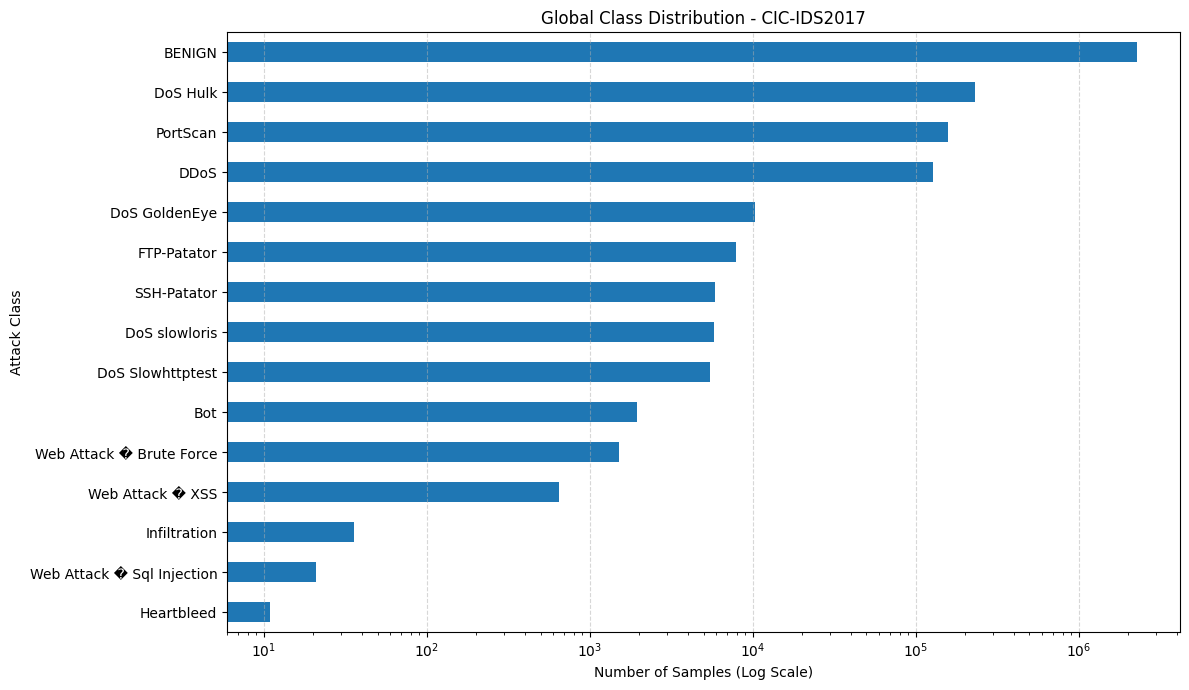

In [20]:
plt.figure(figsize=(12, 7))

global_counts.sort_values().plot(
    kind="barh"
)

plt.xscale("log")

plt.title("Global Class Distribution - CIC-IDS2017")

plt.xlabel("Number of Samples (Log Scale)")
plt.ylabel("Attack Class")

plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Global Class Distribution Analysis

The CIC-IDS2017 dataset contains 2,830,743 network traffic samples distributed across 15 classes.

Key observations:

- BENIGN traffic represents approximately 80.30% of the entire dataset.
- DoS Hulk is the most frequent attack class, representing approximately 8.16%.
- PortScan and DDoS represent approximately 5.61% and 4.52%, respectively.
- Several attack classes are severely underrepresented, especially Heartbleed (11 samples), SQL Injection (21 samples), and Infiltration (36 samples).
- The dataset exhibits significant class imbalance.

**Conclusion:**

Class imbalance must be considered during model development. Accuracy alone will not be sufficient for evaluating the intrusion detection models. Precision, Recall, F1-score, and Confusion Matrix will also be used.

In [21]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    numeric_df = df.select_dtypes(include=np.number)

    inf_count = np.isinf(numeric_df).sum().sum()

    print("Infinity Values:", inf_count)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Infinity Values: 64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Infinity Values: 727

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Infinity Values: 216

Dataset: Monday-WorkingHours.pcap_ISCX.csv
Infinity Values: 810

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Infinity Values: 396

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Infinity Values: 250

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Infinity Values: 327

Dataset: Wednesday-workingHours.pcap_ISCX.csv
Infinity Values: 1586


In [22]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    numeric_df = df.select_dtypes(include=np.number)

    inf_per_column = np.isinf(numeric_df).sum()

    inf_per_column = inf_per_column[inf_per_column > 0]

    print("\nColumns containing Infinity:")
    print(inf_per_column)
    


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s       30
 Flow Packets/s    34
dtype: int64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s       356
 Flow Packets/s    371
dtype: int64

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s        94
 Flow Packets/s    122
dtype: int64

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s       373
 Flow Packets/s    437
dtype: int64

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s       189
 Flow Packets/s    207
dtype: int64

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s       115
 Flow Packets/s    135
dtype: int64

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv

Columns containing Infinity:
Flow Bytes/s        63
 Flow Packets/s  

In [24]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print("Dataset:", name)

    for col in [" Flow Bytes/s", " Flow Packets/s"]:
        values = df[col]

        positive_inf = np.isposinf(values).sum()
        negative_inf = np.isneginf(values).sum()
        nan_count = values.isna().sum()

        print(f"\nColumn: {col.strip()}")
        print("Positive Infinity:", positive_inf)
        print("Negative Infinity:", negative_inf)
        print("NaN:", nan_count)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


KeyError: ' Flow Bytes/s'

In [25]:
for name, df in datasets.items():
    print("\nDataset:", name)

    for col in df.columns:
        if "Flow Bytes/s" in col or "Flow Packets/s" in col:
            print(repr(col))
        


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Monday-WorkingHours.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'

Dataset: Wednesday-workingHours.pcap_ISCX.csv
'Flow Bytes/s'
' Flow Packets/s'


In [27]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print("Dataset:", name)

    for col in ["Flow Bytes/s", " Flow Packets/s"]:

        values = df[col]

        positive_inf = np.isposinf(values).sum()
        negative_inf = np.isneginf(values).sum()

        print(f"\nColumn: {col}")
        print("Positive Infinity:", positive_inf)
        print("Negative Infinity:", negative_inf)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Column: Flow Bytes/s
Positive Infinity: 30
Negative Infinity: 0

Column:  Flow Packets/s
Positive Infinity: 34
Negative Infinity: 0

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Column: Flow Bytes/s
Positive Infinity: 356
Negative Infinity: 0

Column:  Flow Packets/s
Positive Infinity: 371
Negative Infinity: 0

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Column: Flow Bytes/s
Positive Infinity: 94
Negative Infinity: 0

Column:  Flow Packets/s
Positive Infinity: 122
Negative Infinity: 0

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Column: Flow Bytes/s
Positive Infinity: 373
Negative Infinity: 0

Column:  Flow Packets/s
Positive Infinity: 437
Negative Infinity: 0

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Column: Flow Bytes/s
Positive Infinity: 189
Negative Infinity: 0

Column:  Flow Packets/s
Positive Infinity: 207
Negative Infinity: 0

Dataset: Thursday-WorkingHours-Morning-

In [28]:
for name, df in datasets.items():

    bytes_values = df["Flow Bytes/s"]
    packets_values = df[" Flow Packets/s"]

    bytes_inf = np.isinf(bytes_values)
    packets_inf = np.isinf(packets_values)

    bytes_nan = bytes_values.isna()
    packets_nan = packets_values.isna()

    # الصفوف التي تحتوي على Infinity في أي من العمودين
    inf_rows = bytes_inf | packets_inf

    # الصفوف التي تحتوي على NaN في أي من العمودين
    nan_rows = bytes_nan | packets_nan

    # الصفوف التي تحتوي على الاثنين معًا
    overlap = inf_rows & nan_rows

    print("\n" + "=" * 60)
    print("Dataset:", name)

    print("NaN in Flow Bytes/s:", bytes_nan.sum())
    print("NaN in Flow Packets/s:", packets_nan.sum())

    print("Rows containing Infinity:", inf_rows.sum())
    print("Rows containing NaN:", nan_rows.sum())
    print("Rows containing BOTH NaN and Infinity:", overlap.sum())


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
NaN in Flow Bytes/s: 4
NaN in Flow Packets/s: 0
Rows containing Infinity: 34
Rows containing NaN: 4
Rows containing BOTH NaN and Infinity: 4

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
NaN in Flow Bytes/s: 15
NaN in Flow Packets/s: 0
Rows containing Infinity: 371
Rows containing NaN: 15
Rows containing BOTH NaN and Infinity: 15

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
NaN in Flow Bytes/s: 28
NaN in Flow Packets/s: 0
Rows containing Infinity: 122
Rows containing NaN: 28
Rows containing BOTH NaN and Infinity: 28

Dataset: Monday-WorkingHours.pcap_ISCX.csv
NaN in Flow Bytes/s: 64
NaN in Flow Packets/s: 0
Rows containing Infinity: 437
Rows containing NaN: 64
Rows containing BOTH NaN and Infinity: 64

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
NaN in Flow Bytes/s: 18
NaN in Flow Packets/s: 0
Rows containing Infinity: 207
Rows containing NaN: 18
Rows containing BOTH NaN and Infi

In [29]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    constant_columns = []

    for col in df.columns:
        if df[col].nunique(dropna=False) == 1:
            constant_columns.append(col)

    print("Number of Constant Features:", len(constant_columns))
    print("Constant Columns:", constant_columns)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of Constant Features: 10
Constant Columns: [' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' CWE Flag Count', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of Constant Features: 10
Constant Columns: [' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' CWE Flag Count', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of Constant Features: 10
Constant Columns: [' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' CWE Flag Count', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Dataset: Monday-WorkingHours.pcap_ISCX.

In [30]:
common_constant_features = [
    " Bwd PSH Flags",
    " Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    " Fwd Avg Packets/Bulk",
    " Fwd Avg Bulk Rate",
    " Bwd Avg Bytes/Bulk",
    " Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

### Constant Features Analysis

The EDA revealed several constant features across the CIC-IDS2017 datasets.

Key findings:
- 8 features are constant across all 8 datasets.
- CWE Flag Count is constant in 7 datasets.
- Fwd URG Flags is constant in 7 datasets.
- The Monday dataset contains only BENIGN traffic, so its Label column is constant.

These features will be reviewed again after merging the datasets.

Features that remain constant across the complete dataset can be removed during preprocessing because they provide no discriminative information.

The Label column must be preserved as the target variable.

In [31]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    unique_counts = df.nunique(dropna=False)

    print("\nFeatures with 2 to 5 unique values:")
    print(unique_counts[
        (unique_counts >= 2) & (unique_counts <= 5)
    ].sort_values())


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Features with 2 to 5 unique values:
Fwd PSH Flags      2
FIN Flag Count     2
 SYN Flag Count    2
 RST Flag Count    2
 PSH Flag Count    2
 ACK Flag Count    2
 URG Flag Count    2
 ECE Flag Count    2
 Label             2
dtype: int64

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Features with 2 to 5 unique values:
Fwd PSH Flags      2
FIN Flag Count     2
 SYN Flag Count    2
 RST Flag Count    2
 PSH Flag Count    2
 ACK Flag Count    2
 URG Flag Count    2
 ECE Flag Count    2
 Label             2
dtype: int64

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Features with 2 to 5 unique values:
Fwd PSH Flags      2
FIN Flag Count     2
 SYN Flag Count    2
 RST Flag Count    2
 PSH Flag Count    2
 ACK Flag Count    2
 URG Flag Count    2
 ECE Flag Count    2
 Label             2
dtype: int64

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Features with 2 to 5 unique values:
Fwd PSH Flags      2
FIN Fla

In [32]:
binary_features = [
    col for col in reference_columns
    if col != " Label"
    and datasets[next(iter(datasets))][col].nunique(dropna=False) == 2
]

print("Binary Features:")
print(binary_features)

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    for col in binary_features:

        print(f"\n{col}")
        print(df[col].value_counts(dropna=False).to_dict())

Binary Features:
['Fwd PSH Flags', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag Count', ' ECE Flag Count']

Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Fwd PSH Flags
{0: 218245, 1: 7500}

FIN Flag Count
{0: 225142, 1: 603}

 SYN Flag Count
{0: 218245, 1: 7500}

 RST Flag Count
{0: 225718, 1: 27}

 PSH Flag Count
{0: 146472, 1: 79273}

 ACK Flag Count
{1: 113880, 0: 111865}

 URG Flag Count
{0: 193971, 1: 31774}

 ECE Flag Count
{0: 225718, 1: 27}

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Fwd PSH Flags
{0: 280453, 1: 6014}

FIN Flag Count
{0: 283977, 1: 2490}

 SYN Flag Count
{0: 280453, 1: 6014}

 RST Flag Count
{0: 286446, 1: 21}

 PSH Flag Count
{1: 189267, 0: 97200}

 ACK Flag Count
{0: 250912, 1: 35555}

 URG Flag Count
{0: 273670, 1: 12797}

 ECE Flag Count
{0: 286446, 1: 21}

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Fwd PSH Flags
{0: 181297, 1: 9736}

FIN Flag Count
{0: 188

In [33]:
feature_pairs = [
    ("Fwd PSH Flags", " SYN Flag Count"),
    (" RST Flag Count", " ECE Flag Count")
]

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print("Dataset:", name)

    for col1, col2 in feature_pairs:

        identical = df[col1].equals(df[col2])

        different_rows = (df[col1] != df[col2]).sum()

        print(f"\n{col1} vs {col2}")
        print("Exactly Identical:", identical)
        print("Different Rows:", different_rows)


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Fwd PSH Flags vs  SYN Flag Count
Exactly Identical: True
Different Rows: 0

 RST Flag Count vs  ECE Flag Count
Exactly Identical: True
Different Rows: 0

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Fwd PSH Flags vs  SYN Flag Count
Exactly Identical: True
Different Rows: 0

 RST Flag Count vs  ECE Flag Count
Exactly Identical: True
Different Rows: 0

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Fwd PSH Flags vs  SYN Flag Count
Exactly Identical: True
Different Rows: 0

 RST Flag Count vs  ECE Flag Count
Exactly Identical: True
Different Rows: 0

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Fwd PSH Flags vs  SYN Flag Count
Exactly Identical: True
Different Rows: 0

 RST Flag Count vs  ECE Flag Count
Exactly Identical: False
Different Rows: 1

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Fwd PSH Flags vs  SYN Flag Count
Exactly Identical: True
Different Rows: 0

 RST Flag Count vs

In [34]:
for name, df in datasets.items():

    mask = df[" RST Flag Count"] != df[" ECE Flag Count"]

    if mask.any():

        print("\n" + "=" * 60)
        print("Dataset:", name)
        print("Number of Different Rows:", mask.sum())

        mismatched_rows = df.loc[
            mask,
            [" RST Flag Count", " ECE Flag Count", " Label"]
        ]

        display(mismatched_rows)


Dataset: Monday-WorkingHours.pcap_ISCX.csv
Number of Different Rows: 1


,RST Flag Count,ECE Flag Count,Label
336604,0,1,BENIGN



Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Number of Different Rows: 1


,RST Flag Count,ECE Flag Count,Label
259563,0,1,BENIGN



Dataset: Wednesday-workingHours.pcap_ISCX.csv
Number of Different Rows: 1


,RST Flag Count,ECE Flag Count,Label
618068,0,1,BENIGN


### Duplicate Features Analysis

Two pairs of features were investigated:

1. Fwd PSH Flags and SYN Flag Count:
   - These features are exactly identical across all 8 datasets.
   - One of them can be removed during feature selection.

2. RST Flag Count and ECE Flag Count:
   - These features are identical in 5 datasets.
   - Three datasets contain one mismatched row each.
   - Further investigation is required before deciding whether to remove one.

No features have been removed at this stage.

In [35]:
df = datasets["Monday-WorkingHours.pcap_ISCX.csv"]

mask = df[" RST Flag Count"] != df[" ECE Flag Count"]

display(
    df.loc[
        mask,
        [" RST Flag Count", " ECE Flag Count", " Label"]
    ]
)

,RST Flag Count,ECE Flag Count,Label
336604,0,1,BENIGN


In [36]:
for name in [
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv"
]:

    df = datasets[name]

    mask = df[" RST Flag Count"] != df[" ECE Flag Count"]

    print("\nDataset:", name)

    display(
        df.loc[
            mask,
            [" RST Flag Count", " ECE Flag Count", " Label"]
        ]
    )


Dataset: Tuesday-WorkingHours.pcap_ISCX.csv


,RST Flag Count,ECE Flag Count,Label
259563,0,1,BENIGN



Dataset: Wednesday-workingHours.pcap_ISCX.csv


,RST Flag Count,ECE Flag Count,Label
618068,0,1,BENIGN


### Duplicate Features Investigation

The investigation revealed:

1. Fwd PSH Flags and SYN Flag Count:
   - Exactly identical across all 8 datasets.
   - One feature can be removed without losing information.

2. RST Flag Count and ECE Flag Count:
   - Almost identical across all datasets.
   - Only 3 mismatched rows were found across 2,830,743 samples.
   - All mismatches belong to BENIGN traffic.
   - In each mismatch, RST Flag Count = 0 and ECE Flag Count = 1.

The second pair will be retained for now because the features are not perfectly identical.

Final feature selection will be evaluated during model development.

In [37]:
correlation_datasets = {}

for name, df in datasets.items():

    temp_df = df.copy()

    # Clean column names in the temporary copy
    temp_df.columns = temp_df.columns.str.strip()

    # Keep numerical features only
    numeric_df = temp_df.select_dtypes(include=np.number)

    # Replace Infinity with NaN
    numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)

    # Drop columns that are completely empty
    numeric_df = numeric_df.dropna(axis=1, how="all")

    # Fill missing values with median for correlation analysis
    numeric_df = numeric_df.fillna(numeric_df.median())

    correlation_datasets[name] = numeric_df

    print(
        name,
        "| Rows:", numeric_df.shape[0],
        "| Numerical Features:", numeric_df.shape[1]
    )

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv | Rows: 225745 | Numerical Features: 78
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv | Rows: 286467 | Numerical Features: 78
Friday-WorkingHours-Morning.pcap_ISCX.csv | Rows: 191033 | Numerical Features: 78
Monday-WorkingHours.pcap_ISCX.csv | Rows: 529918 | Numerical Features: 78
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv | Rows: 288602 | Numerical Features: 78
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv | Rows: 170366 | Numerical Features: 78
Tuesday-WorkingHours.pcap_ISCX.csv | Rows: 445909 | Numerical Features: 78
Wednesday-workingHours.pcap_ISCX.csv | Rows: 692703 | Numerical Features: 78


In [38]:
for name, df in correlation_datasets.items():

    print("\n" + "=" * 70)
    print("Dataset:", name)

    # Calculate correlation matrix
    corr_matrix = df.corr(method="pearson")

    # Get only the upper triangle to avoid duplicate pairs
    upper_triangle = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    # Extract feature pairs with absolute correlation >= 0.95
    high_corr_pairs = (
        upper_triangle
        .stack()
        .reset_index()
    )

    high_corr_pairs.columns = [
        "Feature 1",
        "Feature 2",
        "Correlation"
    ]

    high_corr_pairs = high_corr_pairs[
        high_corr_pairs["Correlation"].abs() >= 0.95
    ]

    high_corr_pairs["Abs Correlation"] = (
        high_corr_pairs["Correlation"].abs()
    )

    high_corr_pairs = high_corr_pairs.sort_values(
        "Abs Correlation",
        ascending=False
    )

    print(
        "Number of highly correlated pairs:",
        len(high_corr_pairs)
    )

    display(high_corr_pairs.head(15))


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of highly correlated pairs: 49


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
3560,RST Flag Count,ECE Flag Count,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
3172,Packet Length Mean,Average Packet Size,0.999357,0.999357



Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of highly correlated pairs: 54


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
3560,RST Flag Count,ECE Flag Count,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
98,Flow Duration,Fwd IAT Total,0.998805,0.998805



Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of highly correlated pairs: 64


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.00000,1.00000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.00000,1.00000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.00000,1.00000
298,Total Backward Packets,Subflow Bwd Packets,1.00000,1.00000
2384,Fwd PSH Flags,SYN Flag Count,1.00000,1.00000
3560,RST Flag Count,ECE Flag Count,1.00000,1.00000
2707,Fwd Header Length,Fwd Header Length.1,1.00000,1.00000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.00000,1.00000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.00000,1.00000
220,Total Fwd Packets,Subflow Bwd Packets,0.99959,0.99959


... (6 outputs left out)


Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Number of highly correlated pairs: 38


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
4900,Subflow Fwd Packets,Subflow Bwd Packets,0.999477,0.999477
220,Total Fwd Packets,Subflow Bwd Packets,0.999477,0.999477



Dataset: Wednesday-workingHours.pcap_ISCX.csv
Number of highly correlated pairs: 87


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
2794,Bwd Header Length,Subflow Bwd Packets,0.999933,0.999933
269,Total Backward Packets,Bwd Header Length,0.999933,0.999933


In [39]:
all_correlation_pairs = []

for name, df in correlation_datasets.items():

    corr_matrix = df.corr(method="pearson")

    upper_triangle = corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )

    pairs = upper_triangle.stack().reset_index()

    pairs.columns = [
        "Feature 1",
        "Feature 2",
        "Correlation"
    ]

    pairs = pairs[
        pairs["Correlation"].abs() >= 0.95
    ].copy()

    pairs["Dataset"] = name

    all_correlation_pairs.append(pairs)


all_pairs_df = pd.concat(
    all_correlation_pairs,
    ignore_index=True
)

pair_summary = (
    all_pairs_df
    .groupby(["Feature 1", "Feature 2"])
    .agg(
        Dataset_Count=("Dataset", "nunique"),
        Mean_Correlation=("Correlation", "mean"),
        Min_Correlation=("Correlation", "min"),
        Max_Correlation=("Correlation", "max")
    )
    .reset_index()
    .sort_values(
        ["Dataset_Count", "Mean_Correlation"],
        ascending=False
    )
)

display(pair_summary.head(30))

,Feature 1,Feature 2,Dataset_Count,Mean_Correlation,Min_Correlation,Max_Correlation
41,Fwd Header Length,Fwd Header Length.1,8,1.000000,1.000000,1.000000
60,Fwd PSH Flags,SYN Flag Count,8,1.000000,1.000000,1.000000
62,Fwd Packet Length Mean,Avg Fwd Segment Size,8,1.000000,1.000000,1.000000
83,Total Backward Packets,Subflow Bwd Packets,8,1.000000,1.000000,1.000000
92,Total Fwd Packets,Subflow Fwd Packets,8,1.000000,1.000000,1.000000
16,Bwd Packet Length Mean,Avg Bwd Segment Size,8,1.000000,1.000000,1.000000
103,Total Length of Fwd Packets,Subflow Fwd Bytes,8,1.000000,1.000000,1.000000
99,Total Length of Bwd Packets,Subflow Bwd Bytes,8,1.000000,1.000000,1.000000
72,RST Flag Count,ECE Flag Count,8,0.998460,0.993126,1.000000
24,Flow Duration,Fwd IAT Total,8,0.998166,0.997054,0.999268


In [40]:
candidate_pairs = [
    ("Fwd Header Length", "Fwd Header Length.1"),
    ("Fwd PSH Flags", "SYN Flag Count"),
    ("Fwd Packet Length Mean", "Avg Fwd Segment Size"),
    ("Total Backward Packets", "Subflow Bwd Packets"),
    ("Total Fwd Packets", "Subflow Fwd Packets"),
    ("Bwd Packet Length Mean", "Avg Bwd Segment Size"),
    ("Total Length of Fwd Packets", "Subflow Fwd Bytes"),
    ("Total Length of Bwd Packets", "Subflow Bwd Bytes")
]

for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    print("\n" + "=" * 70)
    print("Dataset:", name)

    for feature1, feature2 in candidate_pairs:

        differences = (
            df[feature1] != df[feature2]
        ).sum()

        print(
            f"{feature1} vs {feature2}: "
            f"{differences} different rows"
        )


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Fwd Header Length vs Fwd Header Length.1: 0 different rows
Fwd PSH Flags vs SYN Flag Count: 0 different rows
Fwd Packet Length Mean vs Avg Fwd Segment Size: 0 different rows
Total Backward Packets vs Subflow Bwd Packets: 0 different rows
Total Fwd Packets vs Subflow Fwd Packets: 0 different rows
Bwd Packet Length Mean vs Avg Bwd Segment Size: 2 different rows
Total Length of Fwd Packets vs Subflow Fwd Bytes: 0 different rows
Total Length of Bwd Packets vs Subflow Bwd Bytes: 0 different rows

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Fwd Header Length vs Fwd Header Length.1: 0 different rows
Fwd PSH Flags vs SYN Flag Count: 0 different rows
Fwd Packet Length Mean vs Avg Fwd Segment Size: 0 different rows
Total Backward Packets vs Subflow Bwd Packets: 0 different rows
Total Fwd Packets vs Subflow Fwd Packets: 0 different rows
Bwd Packet Length Mean vs Avg Bwd Segment Size: 2 different rows
Total Length of Fwd 

In [41]:
pairs_to_investigate = [
    ("Bwd Packet Length Mean", "Avg Bwd Segment Size"),
    ("Total Length of Bwd Packets", "Subflow Bwd Bytes"),
    ("Total Length of Fwd Packets", "Subflow Fwd Bytes"),
    ("Fwd Packet Length Mean", "Avg Fwd Segment Size")
]

for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    print("\n" + "=" * 70)
    print("Dataset:", name)

    for col1, col2 in pairs_to_investigate:

        a = df[col1]
        b = df[col2]

        different = a.ne(b)
        close = np.isclose(
            a,
            b,
            rtol=1e-9,
            atol=1e-12,
            equal_nan=True
        )

        mismatch_count = different.sum()
        real_difference_count = (~close).sum()

        if mismatch_count > 0:
            print(f"\n{col1} vs {col2}")
            print("Exact differences:", mismatch_count)
            print("Differences beyond tolerance:", real_difference_count)
            print("Maximum absolute difference:",
                  (a - b).abs().max())


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Bwd Packet Length Mean vs Avg Bwd Segment Size
Exact differences: 2
Differences beyond tolerance: 0
Maximum absolute difference: 9.99999883788405e-07

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Bwd Packet Length Mean vs Avg Bwd Segment Size
Exact differences: 2
Differences beyond tolerance: 0
Maximum absolute difference: 9.99999883788405e-07

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Bwd Packet Length Mean vs Avg Bwd Segment Size
Exact differences: 5
Differences beyond tolerance: 0
Maximum absolute difference: 1.0000003385357559e-06

Total Length of Bwd Packets vs Subflow Bwd Bytes
Exact differences: 28
Differences beyond tolerance: 28
Maximum absolute difference: 421277

Dataset: Monday-WorkingHours.pcap_ISCX.csv

Bwd Packet Length Mean vs Avg Bwd Segment Size
Exact differences: 35
Differences beyond tolerance: 0
Maximum absolute difference: 1.000444171950221e-10

Fwd Packet Length Mean vs Avg Fw

In [42]:
pairs_to_check = [
    ("Total Length of Bwd Packets", "Subflow Bwd Bytes"),
    ("Total Length of Fwd Packets", "Subflow Fwd Bytes")
]

for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    print("\n" + "=" * 80)
    print("Dataset:", name)

    for col1, col2 in pairs_to_check:

        different = df[col1] != df[col2]

        if different.any():

            print(f"\n{col1} vs {col2}")

            samples = df.loc[
                different,
                [
                    col1,
                    col2,
                    "Total Fwd Packets",
                    "Total Backward Packets",
                    "Subflow Fwd Packets",
                    "Subflow Bwd Packets",
                    "Label"
                ]
            ].copy()

            samples["Absolute Difference"] = (
                samples[col1] - samples[col2]
            ).abs()

            display(
                samples.sort_values(
                    "Absolute Difference",
                    ascending=False
                ).head(5)
            )


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Total Length of Bwd Packets vs Subflow Bwd Bytes


,Total Length of Bwd Packets,Subflow Bwd Bytes,Total Fwd Packets,Total Backward Packets,Subflow Fwd Packets,Subflow Bwd Packets,Label,Absolute Difference
18353,227000000,227421277,77620,104354,77620,104354,BENIGN,421277
12729,611000000,611320795,207964,284602,207964,284602,BENIGN,320795
14255,607000000,606685970,206687,281741,206687,281741,BENIGN,314030
14876,578000000,578312590,197473,265615,197473,265615,BENIGN,312590
10067,470000000,470107793,160325,218124,160325,218124,BENIGN,107793



Dataset: Monday-WorkingHours.pcap_ISCX.csv

Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Total Length of Bwd Packets vs Subflow Bwd Bytes


,Total Length of Bwd Packets,Subflow Bwd Bytes,Total Fwd Packets,Total Backward Packets,Subflow Fwd Packets,Subflow Bwd Packets,Label,Absolute Difference
194786,23600000,23647262,8040,11029,8040,11029,BENIGN,47262
45972,27400000,27362171,9692,12392,9692,12392,BENIGN,37829
195046,21500000,21465814,10589,9351,10589,9351,BENIGN,34186
97395,27400000,27374343,9399,12296,9399,12296,BENIGN,25657
69459,27300000,27322281,8903,13243,8903,13243,BENIGN,22281



Total Length of Fwd Packets vs Subflow Fwd Bytes


,Total Length of Fwd Packets,Subflow Fwd Bytes,Total Fwd Packets,Total Backward Packets,Subflow Fwd Packets,Subflow Bwd Packets,Label,Absolute Difference
103957,12900000,12870338,9453,4828,9453,4828,BENIGN,29662


... (2 outputs left out)


Dataset: Tuesday-WorkingHours.pcap_ISCX.csv

Total Length of Bwd Packets vs Subflow Bwd Bytes


,Total Length of Bwd Packets,Subflow Bwd Bytes,Total Fwd Packets,Total Backward Packets,Subflow Fwd Packets,Subflow Bwd Packets,Label,Absolute Difference
21908,474000000,473567060,162890,228618,162890,228618,BENIGN,432940
15761,538000000,537584897,180725,242974,180725,242974,BENIGN,415103
377349,255000000,255393462,86656,115838,86656,115838,BENIGN,393462
23319,399000000,399392754,123228,170795,123228,170795,BENIGN,392754
302584,131000000,130657206,44739,63120,44739,63120,BENIGN,342794



Dataset: Wednesday-workingHours.pcap_ISCX.csv

Total Length of Bwd Packets vs Subflow Bwd Bytes


,Total Length of Bwd Packets,Subflow Bwd Bytes,Total Fwd Packets,Total Backward Packets,Subflow Fwd Packets,Subflow Bwd Packets,Label,Absolute Difference
5321,585000000,584509539,199565,268604,199565,268604,BENIGN,490461
721,584000000,583510015,203943,263412,203943,263412,BENIGN,489985
6526,593000000,593469129,202456,272353,202456,272353,BENIGN,469129
4200,347000000,346573861,121885,158184,121885,158184,BENIGN,426139
9936,399000000,399368696,112141,157388,112141,157388,BENIGN,368696


In [43]:
for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    col1 = "Total Length of Bwd Packets"
    col2 = "Subflow Bwd Bytes"

    different = df[col1] != df[col2]

    if different.sum() == 0:
        continue

    diff_df = df.loc[different, [col1, col2, "Label"]].copy()

    diff_df["Absolute Difference"] = (
        diff_df[col1] - diff_df[col2]
    ).abs()

    diff_df["Relative Difference %"] = (
        diff_df["Absolute Difference"]
        / diff_df[col2].abs().replace(0, np.nan)
    ) * 100

    print("\n" + "=" * 70)
    print("Dataset:", name)

    print("\nDifferences by Label:")
    display(
        diff_df.groupby("Label").agg(
            Count=("Absolute Difference", "size"),
            Mean_Difference=("Absolute Difference", "mean"),
            Max_Difference=("Absolute Difference", "max"),
            Mean_Relative_Difference=(
                "Relative Difference %",
                "mean"
            )
        ).sort_values("Count", ascending=False)
    )

    print("\nOverall Statistics:")
    display(
        diff_df[
            ["Absolute Difference", "Relative Difference %"]
        ].describe()
    )


Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv

Differences by Label:


,Count,Mean_Difference,Max_Difference,Mean_Relative_Difference
Label,,,,
BENIGN,28,70085.75,421277,0.069394



Overall Statistics:


,Absolute Difference,Relative Difference %
count,28.00000,28.000000
mean,70085.75000,0.069394
std,116977.21389,0.062211
min,1269.00000,0.006295
25%,8450.00000,0.022415
50%,20489.00000,0.047147
75%,42792.25000,0.081455
max,421277.00000,0.212168



Dataset: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Differences by Label:


,Count,Mean_Difference,Max_Difference,Mean_Relative_Difference
Label,,,,
BENIGN,8,23705.25,47262,0.095426


... (10 outputs left out)


Dataset: Wednesday-workingHours.pcap_ISCX.csv

Differences by Label:


,Count,Mean_Difference,Max_Difference,Mean_Relative_Difference
Label,,,,
BENIGN,44,101521.272727,490461,0.100729



Overall Statistics:


,Absolute Difference,Relative Difference %
count,44.000000,44.000000
mean,101521.272727,0.100729
std,152366.452550,0.085750
min,799.000000,0.001525
25%,13990.500000,0.036848
50%,29580.000000,0.081479
75%,57225.500000,0.139899
max,490461.000000,0.349058


### Correlation Analysis

Pearson correlation analysis was performed separately on all eight CIC-IDS2017 datasets using the 78 numerical features.

A correlation threshold of |r| >= 0.95 was used to identify highly correlated feature pairs.

**Key Findings:**

- A total of 446 highly correlated pairs were identified across the eight datasets.
- Eight feature pairs showed a correlation of 1.0 across all datasets.
- Further row-by-row comparison confirmed four pairs to be exactly identical across all eight datasets:
  - `Fwd Header Length` and `Fwd Header Length.1`
  - `Fwd PSH Flags` and `SYN Flag Count`
  - `Total Backward Packets` and `Subflow Bwd Packets`
  - `Total Fwd Packets` and `Subflow Fwd Packets`
- Some other pairs showed extremely small floating-point differences, while others contained actual numerical differences.
- In particular, `Total Length of Bwd Packets` and `Subflow Bwd Bytes` differed in 146 rows across five datasets. All identified mismatches belonged to the BENIGN class.
- High correlation does not necessarily indicate exact equality or identical feature meaning.

**Conclusion:**

Highly correlated features may introduce redundancy and increase model complexity. However, feature removal will be postponed until preprocessing and model evaluation. The original raw datasets will remain unchanged.

In [44]:
for name, df in correlation_datasets.items():

    print("\n" + "=" * 70)
    print("Dataset:", name)

    # Calculate correlation matrix
    corr_matrix = df.corr(method="pearson")

    # Get only the upper triangle to avoid duplicate pairs
    upper_triangle = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    # Extract feature pairs with absolute correlation >= 0.95
    high_corr_pairs = (
        upper_triangle
        .stack()
        .reset_index()
    )

    high_corr_pairs.columns = [
        "Feature 1",
        "Feature 2",
        "Correlation"
    ]

    high_corr_pairs = high_corr_pairs[
        high_corr_pairs["Correlation"].abs() >= 0.95
    ]

    high_corr_pairs["Abs Correlation"] = (
        high_corr_pairs["Correlation"].abs()
    )

    high_corr_pairs = high_corr_pairs.sort_values(
        "Abs Correlation",
        ascending=False
    )

    print(
        "Number of highly correlated pairs:",
        len(high_corr_pairs)
    )

    display(high_corr_pairs.head(15))


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of highly correlated pairs: 49


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
3560,RST Flag Count,ECE Flag Count,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
3172,Packet Length Mean,Average Packet Size,0.999357,0.999357



Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of highly correlated pairs: 54


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
3560,RST Flag Count,ECE Flag Count,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
98,Flow Duration,Fwd IAT Total,0.998805,0.998805



Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of highly correlated pairs: 64


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.00000,1.00000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.00000,1.00000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.00000,1.00000
298,Total Backward Packets,Subflow Bwd Packets,1.00000,1.00000
2384,Fwd PSH Flags,SYN Flag Count,1.00000,1.00000
3560,RST Flag Count,ECE Flag Count,1.00000,1.00000
2707,Fwd Header Length,Fwd Header Length.1,1.00000,1.00000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.00000,1.00000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.00000,1.00000
220,Total Fwd Packets,Subflow Bwd Packets,0.99959,0.99959


... (6 outputs left out)


Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Number of highly correlated pairs: 38


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
4900,Subflow Fwd Packets,Subflow Bwd Packets,0.999477,0.999477
220,Total Fwd Packets,Subflow Bwd Packets,0.999477,0.999477



Dataset: Wednesday-workingHours.pcap_ISCX.csv
Number of highly correlated pairs: 87


,Feature 1,Feature 2,Correlation,Abs Correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
298,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
2384,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2707,Fwd Header Length,Fwd Header Length.1,1.000000,1.000000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
2794,Bwd Header Length,Subflow Bwd Packets,0.999933,0.999933
269,Total Backward Packets,Bwd Header Length,0.999933,0.999933


In [45]:
outlier_summary = {}

for name, df in correlation_datasets.items():

    print("\n" + "=" * 70)
    print("Dataset:", name)

    Q1 = df.quantile(0.25)
    Q3 = df.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df < lower_bound) |
        (df > upper_bound)
    )

    outlier_counts = outliers.sum()

    summary = pd.DataFrame({
        "Outlier Count": outlier_counts,
        "Outlier Percentage": (
            outlier_counts / len(df) * 100
        ).round(2)
    })

    summary = summary.sort_values(
        "Outlier Count",
        ascending=False
    )

    outlier_summary[name] = summary

    display(summary.head(15))


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


,Outlier Count,Outlier Percentage
Destination Port,88794,39.33
Flow Bytes/s,46400,20.55
Active Mean,43738,19.37
Active Max,43738,19.37
Active Min,43648,19.34
Bwd Packets/s,40923,18.13
Fwd Packets/s,39806,17.63
Flow Packets/s,39146,17.34
Subflow Fwd Bytes,37478,16.60
Total Length of Fwd Packets,37478,16.60



Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv


,Outlier Count,Outlier Percentage
Bwd Packet Length Min,118017,41.20
Fwd IAT Total,63751,22.25
Fwd IAT Max,63456,22.15
Fwd IAT Mean,63337,22.11
Bwd IAT Min,62968,21.98
Packet Length Variance,61032,21.31
Flow IAT Std,60563,21.14
Fwd Packet Length Min,60334,21.06
Min Packet Length,60197,21.01
Flow IAT Mean,57303,20.00



Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv


,Outlier Count,Outlier Percentage
Bwd IAT Mean,45516,23.83
Bwd IAT Total,45246,23.68
Bwd Packet Length Std,44647,23.37
Flow IAT Max,43950,23.01
Bwd IAT Std,43911,22.99
Flow Duration,43798,22.93
Fwd IAT Total,43707,22.88
Fwd IAT Max,43318,22.68
PSH Flag Count,43302,22.67
Flow IAT Std,42995,22.51


... (6 outputs left out)


Dataset: Tuesday-WorkingHours.pcap_ISCX.csv


,Outlier Count,Outlier Percentage
Bwd IAT Std,109438,24.54
Bwd Packet Length Std,108778,24.39
PSH Flag Count,108176,24.26
Bwd IAT Min,107182,24.04
Subflow Bwd Packets,104038,23.33
Total Backward Packets,104038,23.33
Flow IAT Max,103756,23.27
Flow Duration,102824,23.06
Flow Bytes/s,102129,22.90
Fwd IAT Total,101765,22.82



Dataset: Wednesday-workingHours.pcap_ISCX.csv


,Outlier Count,Outlier Percentage
Idle Max,164711,23.78
Flow IAT Std,162259,23.42
Idle Min,162174,23.41
Idle Mean,162083,23.40
Init_Win_bytes_forward,158764,22.92
Flow Bytes/s,157731,22.77
Fwd IAT Std,157457,22.73
Fwd IAT Max,153422,22.15
Flow IAT Max,152827,22.06
Fwd IAT Min,148410,21.42


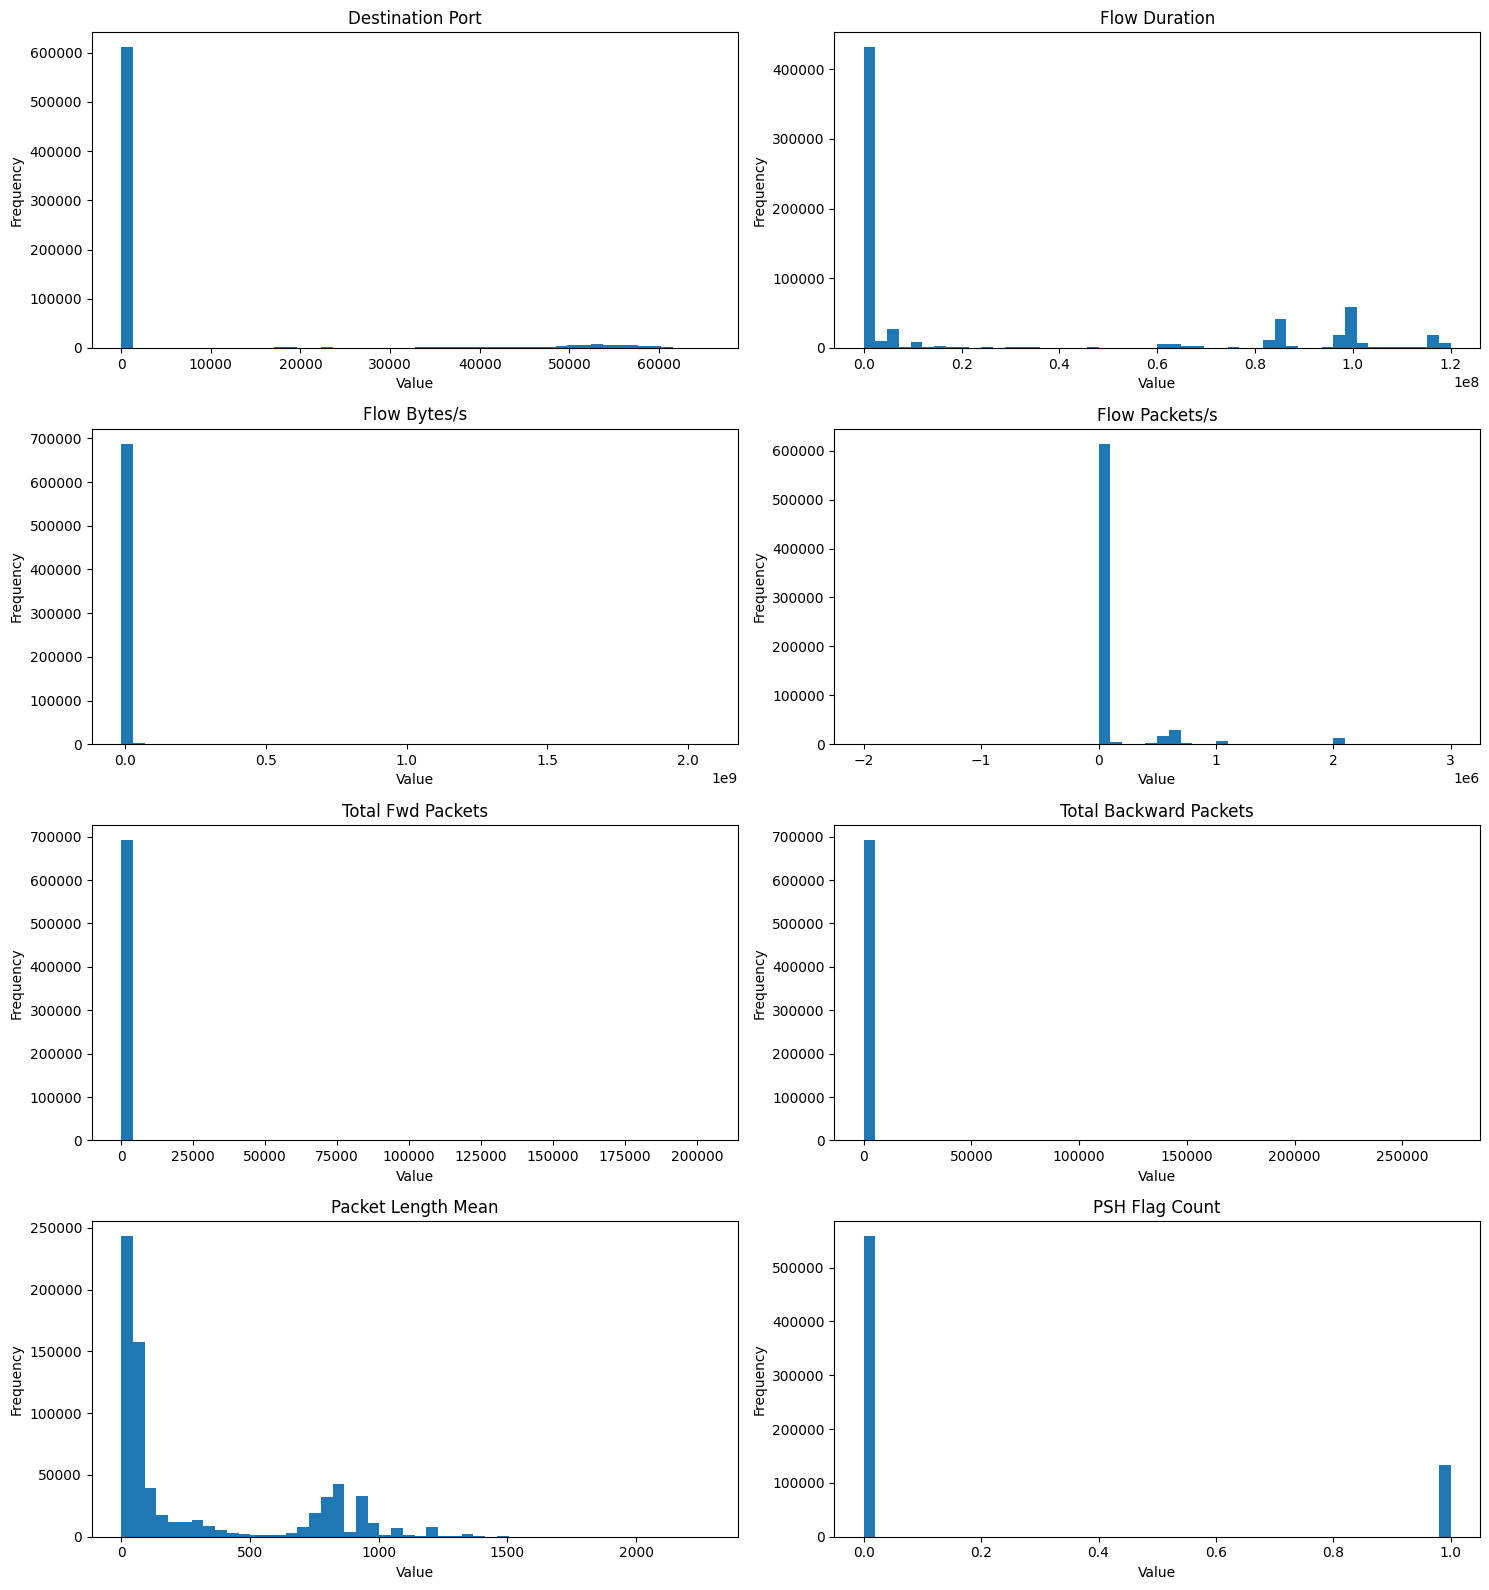

In [46]:
selected_features = [
    "Destination Port",
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean",
    "PSH Flag Count"
]

df = correlation_datasets[
    "Wednesday-workingHours.pcap_ISCX.csv"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for feature, ax in zip(selected_features, axes.flatten()):

    ax.hist(df[feature], bins=50)

    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [48]:
selected_features = [
    "Destination Port",
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean",
    "PSH Flag Count"
]

df = correlation_datasets[
    "Wednesday-workingHours.pcap_ISCX.csv"
]

distribution_report = []

for feature in selected_features:

    series = df[feature]

    distribution_report.append({
        "Feature": feature,
        "Min": series.min(),
        "Max": series.max(),
        "Median": series.median(),
        "99th Percentile": series.quantile(0.99),
        "Negative Count": (series < 0).sum(),
        "Zero Count": (series == 0).sum(),
        "Negative %": round((series < 0).mean() * 100, 4),
        "Zero %": round((series == 0).mean() * 100, 2),
        "Skewness": series.skew()
    })

distribution_report = pd.DataFrame(distribution_report)

display(distribution_report)

,Feature,Min,Max,Median,99th Percentile,Negative Count,Zero Count,Negative %,Zero %,Skewness
0,Destination Port,0.0,6.548700e+04,80.000000,5.876600e+04,0,330,0.0000,0.05,2.595529
1,Flow Duration,-1.0,1.200000e+08,61437.000000,1.177202e+08,21,1297,0.0030,0.19,1.020935
2,Flow Bytes/s,-12000000.0,2.070000e+09,515.510020,1.230000e+07,16,113267,0.0023,16.35,37.876760
3,Flow Packets/s,-2000000.0,3.000000e+06,62.996590,2.000000e+06,21,0,0.0030,0.00,4.392257
4,Total Fwd Packets,1.0,2.039430e+05,2.000000,4.200000e+01,0,0,0.0000,0.00,244.232775
5,Total Backward Packets,0.0,2.723530e+05,2.000000,4.600000e+01,0,134691,0.0000,19.44,245.605889
6,Packet Length Mean,0.0,2.279754e+03,70.454545,1.195300e+03,0,114275,0.0000,16.50,1.121727
7,PSH Flag Count,0.0,1.000000e+00,0.000000,1.000000e+00,0,558531,0.0000,80.63,1.550172


In [49]:
negative_summary = []

selected_features = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s"
]

for name, df in correlation_datasets.items():

    for feature in selected_features:

        negative_values = df.loc[df[feature] < 0, feature]

        negative_summary.append({
            "Dataset": name,
            "Feature": feature,
            "Negative Count": len(negative_values),
            "Min Negative Value": (
                negative_values.min()
                if len(negative_values) > 0
                else np.nan
            ),
            "Max Negative Value": (
                negative_values.max()
                if len(negative_values) > 0
                else np.nan
            )
        })

negative_report = pd.DataFrame(negative_summary)

display(
    negative_report[
        negative_report["Negative Count"] > 0
    ]
)

,Dataset,Feature,Negative Count,Min Negative Value,Max Negative Value
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Duration,2,-1.0,-1.000000e+00
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Bytes/s,2,-12000000.0,-1.200000e+07
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Packets/s,2,-2000000.0,-2.000000e+06
3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Duration,36,-13.0,-1.000000e+00
4,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Bytes/s,36,-193000000.0,-4.615385e+05
5,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Packets/s,36,-2000000.0,-1.538462e+05
6,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Duration,9,-12.0,-1.000000e+00
7,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Bytes/s,8,-12000000.0,-1.000000e+06
8,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Packets/s,9,-2000000.0,-1.666667e+05
9,Monday-WorkingHours.pcap_ISCX.csv,Flow Duration,15,-1.0,-1.000000e+00


In [50]:
negative_features = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s"
]

for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    # Identify rows containing at least one negative value
    negative_mask = (df[negative_features] < 0).any(axis=1)

    negative_df = df.loc[
        negative_mask,
        negative_features + ["Label"]
    ].copy()

    if negative_df.empty:
        continue

    print("\n" + "=" * 70)
    print("Dataset:", name)
    print("Total affected rows:", len(negative_df))

    print("\nNegative rows grouped by Label:")

    display(
        negative_df.groupby("Label").agg(
            Count=("Label", "size"),
            Negative_Duration=(
                "Flow Duration",
                lambda x: (x < 0).sum()
            ),
            Negative_Bytes=(
                "Flow Bytes/s",
                lambda x: (x < 0).sum()
            ),
            Negative_Packets=(
                "Flow Packets/s",
                lambda x: (x < 0).sum()
            )
        ).sort_values("Count", ascending=False)
    )

    print("\nSample affected rows:")

    display(negative_df.head(10))


Dataset: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total affected rows: 2

Negative rows grouped by Label:


,Count,Negative_Duration,Negative_Bytes,Negative_Packets
Label,,,,
BENIGN,2,2,2,2



Sample affected rows:


,Flow Duration,Flow Bytes/s,Flow Packets/s,Label
200991,-1,-12000000.0,-2000000.0,BENIGN
224100,-1,-12000000.0,-2000000.0,BENIGN



Dataset: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total affected rows: 36

Negative rows grouped by Label:


,Count,Negative_Duration,Negative_Bytes,Negative_Packets
Label,,,,
BENIGN,36,36,36,36


... (22 outputs left out)


Dataset: Wednesday-workingHours.pcap_ISCX.csv
Total affected rows: 21

Negative rows grouped by Label:


,Count,Negative_Duration,Negative_Bytes,Negative_Packets
Label,,,,
BENIGN,21,21,16,21



Sample affected rows:


,Flow Duration,Flow Bytes/s,Flow Packets/s,Label
1603,-1,-12000000.0,-2000000.0,BENIGN
19628,-1,-12000000.0,-2000000.0,BENIGN
22705,-1,-12000000.0,-2000000.0,BENIGN
34381,-1,-12000000.0,-2000000.0,BENIGN
174361,-1,-12000000.0,-2000000.0,BENIGN
355144,-1,0.0,-2000000.0,BENIGN
394640,-1,0.0,-2000000.0,BENIGN
426505,-1,-12000000.0,-2000000.0,BENIGN
433139,-1,-12000000.0,-2000000.0,BENIGN
440538,-1,0.0,-2000000.0,BENIGN


In [51]:
for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    mask = (
        (df["Flow Duration"] < 0) &
        (df["Flow Bytes/s"] >= 0)
    )

    affected = df.loc[
        mask,
        [
            "Flow Duration",
            "Total Fwd Packets",
            "Total Backward Packets",
            "Total Length of Fwd Packets",
            "Total Length of Bwd Packets",
            "Flow Bytes/s",
            "Flow Packets/s",
            "Label"
        ]
    ]

    if not affected.empty:
        print("\n" + "=" * 70)
        print("Dataset:", name)
        print("Affected rows:", len(affected))

        display(affected)


Dataset: Friday-WorkingHours-Morning.pcap_ISCX.csv
Affected rows: 1


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
17562,-1,1,1,0,0,0.0,-2000000.0,BENIGN



Dataset: Monday-WorkingHours.pcap_ISCX.csv
Affected rows: 6


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
79642,-1,1,1,0,0,0.0,-2000000.0,BENIGN
111443,-1,1,1,0,0,0.0,-2000000.0,BENIGN
151670,-1,1,1,0,0,0.0,-2000000.0,BENIGN
286677,-1,1,1,0,0,0.0,-2000000.0,BENIGN
362906,-1,1,1,0,0,0.0,-2000000.0,BENIGN
451865,-1,1,1,0,0,0.0,-2000000.0,BENIGN



Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Affected rows: 1


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
129761,-1,1,1,0,0,0.0,-2000000.0,BENIGN



Dataset: Tuesday-WorkingHours.pcap_ISCX.csv
Affected rows: 17


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
24737,-1,1,1,0,0,0.0,-2000000.0,BENIGN
27021,-1,1,1,0,0,0.0,-2000000.0,BENIGN
74737,-1,1,1,0,0,0.0,-2000000.0,BENIGN
90837,-1,1,1,0,0,0.0,-2000000.0,BENIGN
103704,-1,1,1,0,0,0.0,-2000000.0,BENIGN
112258,-1,1,1,0,0,0.0,-2000000.0,BENIGN
119674,-1,1,1,0,0,0.0,-2000000.0,BENIGN
124890,-1,1,1,0,0,0.0,-2000000.0,BENIGN
142333,-1,1,1,0,0,0.0,-2000000.0,BENIGN
203778,-1,1,1,0,0,0.0,-2000000.0,BENIGN



Dataset: Wednesday-workingHours.pcap_ISCX.csv
Affected rows: 5


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
355144,-1,1,1,0,0,0.0,-2000000.0,BENIGN
394640,-1,1,1,0,0,0.0,-2000000.0,BENIGN
440538,-1,1,1,0,0,0.0,-2000000.0,BENIGN
485435,-1,1,1,0,0,0.0,-2000000.0,BENIGN
506357,-1,1,1,0,0,0.0,-2000000.0,BENIGN


### Investigation of Negative Values

Negative values were identified in three numerical features:

- `Flow Duration`
- `Flow Bytes/s`
- `Flow Packets/s`

Across the eight datasets, the investigation identified:

- 115 rows with negative `Flow Duration`.
- 115 rows with negative `Flow Packets/s`.
- 85 rows with negative `Flow Bytes/s`.
- All affected rows were labeled as `BENIGN`.

Further inspection revealed 30 rows where `Flow Duration` and `Flow Packets/s` were negative while `Flow Bytes/s` was zero.

These records also shared the following characteristics:
- One forward packet.
- One backward packet.
- Zero forward packet length.
- Zero backward packet length.

**Conclusion:**

The negative values appear to represent invalid or incorrectly calculated flow measurements rather than meaningful network behavior.

These records will be flagged for further investigation. No rows will be removed from the original raw datasets. Their treatment will be evaluated during preprocessing.

In [52]:
quality_summary = []

for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    numeric_df = df.select_dtypes(include=np.number)

    missing_rows = df.isna().any(axis=1).sum()

    infinity_rows = np.isinf(numeric_df).any(axis=1).sum()

    negative_rows = (
        (df[[
            "Flow Duration",
            "Flow Bytes/s",
            "Flow Packets/s"
        ]] < 0).any(axis=1)
    ).sum()

    quality_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Missing Rows": missing_rows,
        "Infinity Rows": infinity_rows,
        "Negative Rows": negative_rows
    })

quality_report = pd.DataFrame(quality_summary)

display(quality_report)

,Dataset,Total Rows,Missing Rows,Infinity Rows,Negative Rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,4,34,2
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,15,371,36
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,28,122,9
3,Monday-WorkingHours.pcap_ISCX.csv,529918,64,437,15
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,18,207,4
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,20,135,11
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,201,264,17
7,Wednesday-workingHours.pcap_ISCX.csv,692703,1008,1297,21


In [53]:
final_quality_summary = []

for name, original_df in datasets.items():

    df = original_df.copy()
    df.columns = df.columns.str.strip()

    numeric_df = df.select_dtypes(include=np.number)

    missing_mask = df.isna().any(axis=1)

    infinity_mask = np.isinf(numeric_df).any(axis=1)

    negative_mask = (
        (df[[
            "Flow Duration",
            "Flow Bytes/s",
            "Flow Packets/s"
        ]] < 0).any(axis=1)
    )

    problematic_mask = (
        missing_mask |
        infinity_mask |
        negative_mask
    )

    final_quality_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Missing Rows": missing_mask.sum(),
        "Infinity Rows": infinity_mask.sum(),
        "Negative Rows": negative_mask.sum(),
        "Unique Problematic Rows": problematic_mask.sum(),
        "Problematic Percentage": round(
            problematic_mask.mean() * 100, 4
        )
    })

final_quality_report = pd.DataFrame(final_quality_summary)

display(final_quality_report)

,Dataset,Total Rows,Missing Rows,Infinity Rows,Negative Rows,Unique Problematic Rows,Problematic Percentage
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,4,34,2,36,0.0159
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,15,371,36,407,0.1421
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,28,122,9,131,0.0686
3,Monday-WorkingHours.pcap_ISCX.csv,529918,64,437,15,452,0.0853
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,18,207,4,211,0.0731
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,20,135,11,146,0.0857
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,201,264,17,281,0.0630
7,Wednesday-workingHours.pcap_ISCX.csv,692703,1008,1297,21,1318,0.1903


### Data Quality Summary

A final data quality investigation was performed across all eight datasets to identify rows affected by missing values, infinite values, and negative values.

The investigation identified:

- 1,358 rows containing missing values.
- 2,667 rows containing infinite values.
- 115 rows containing negative values in the investigated flow features.
- 2,982 unique rows affected by at least one of these issues.

The total number of unique problematic rows represents approximately **0.1053%** of the complete dataset (2,830,743 rows).

Wednesday's dataset contains the highest number of problematic rows (1,318), while Friday's DDoS dataset has the lowest problematic percentage (0.0159%).

**Conclusion:**

The overall percentage of problematic rows is relatively small. However, these records will not be removed automatically. Each issue will be investigated and handled during the preprocessing stage to avoid unnecessary data loss and preserve potentially useful network traffic information.

The original raw datasets will remain unchanged.

In [54]:
for name, df in datasets.items():

    labels = df[" Label"].dropna().unique()

    suspicious_labels = [
        label for label in labels
        if "\ufffd" in str(label)
    ]

    if suspicious_labels:
        print(f"\nDataset: {name}")
        print("Suspicious Labels:")

        for label in suspicious_labels:
            print(repr(label))


Dataset: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Suspicious Labels:
'Web Attack � Brute Force'
'Web Attack � XSS'
'Web Attack � Sql Injection'


In [55]:
file_path = os.path.join(
    DATA_PATH,
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

with open(file_path, "rb") as f:
    content = f.read()

print("Contains UTF-8 replacement character:",
      b"\xef\xbf\xbd" in content)

print("\nRaw bytes around suspicious label:")

position = content.find(b"Web Attack")

print(content[position:position + 100])

Contains UTF-8 replacement character: True

Raw bytes around suspicious label:
b'Web Attack \xef\xbf\xbd Brute Force\n80,259762,4,4,207,1709,195,0,51.75,95.54187564,1697,0,427.25,846.5047253,'


### Investigation of Label Encoding Issues

During label inspection, three suspicious class names were identified in the Thursday WebAttacks dataset:

- `Web Attack � Brute Force`
- `Web Attack � XSS`
- `Web Attack � Sql Injection`

A binary-level inspection of the original CSV file confirmed that the UTF-8 replacement character (`U+FFFD`) is already stored in the file.

Therefore, this issue does not originate from Pandas CSV loading or the selected encoding parameter. The original character was likely lost or replaced before the dataset was provided.

**Conclusion:**

The original labels will remain unchanged in the raw dataset. During preprocessing, these labels can be normalized to consistent names while preserving their original attack-class meanings.